In [1]:
from collections import Counter
import pandas as pd
from sklearn.mixture import GaussianMixture
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import sklearn
from sklearn.ensemble import RandomForestClassifier
import shap

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\296×87.xlsx")
X = data.iloc[:, 3:]
print(X)
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)


     band_gap     vbm    efermi   density  MagpieData mean MendeleevNumber  \
0      3.9641  1.5315  1.620862  3.963466                        62.944444   
1      4.0463  1.2514  5.297637  3.445198                        68.166667   
2      4.8124  1.1115  1.119990  3.694735                        71.093750   
3      5.7528 -0.4329 -0.340741  2.386433                        75.461538   
4      3.5597  4.1619  4.190622  3.471804                        54.888889   
..        ...     ...       ...       ...                              ...   
291    3.1158  0.8977  1.028221  4.490112                        71.000000   
292    3.8987  1.4788  1.577688  3.951200                        70.833333   
293    4.4213  1.3729  2.409320  3.611433                        66.083333   
294    5.3908  1.2574  1.237219  3.592312                        72.681818   
295    4.2023  2.0134  2.000341  3.669853                        70.750000   

     MagpieData minimum AtomicWeight  MagpieData range MeltingT

In [2]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\benchmark4.xlsx"
reported_structures = extract_numbers(file_path)
print(reported_structures)

[14, 15, 16, 17, 95, 111, 142, 144, 153, 157, 171, 180, 199, 261, 283]


In [3]:
pca = PCA(n_components= 0.7, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)


i = 5
GMM = GaussianMixture(n_components=i, covariance_type='full', init_params = 'random', reg_covar= 1e-5, tol  =  1e-4 , random_state=42)
GMM.fit(new_data)
labels = GMM.predict(new_data)
print(f"Silhouette score: {silhouette_score(new_data, labels):.2f}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")
df = pd.DataFrame(labels)
df.to_excel("GMM_result.xlsx")

data[f'cluster_{i}'] = labels

print(f"\nNumber of clusters k={i}:")


for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]
            # print(cluster_samples)

    total_in_cluster = len(cluster_samples)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])

    print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")

(296, 10)
Silhouette score: 0.08
Calinski-Harabasz score: 33.72

Number of clusters k=5:
Cluster 0: 0/44 (Reported ratio: 0.00%)
Cluster 1: 0/37 (Reported ratio: 0.00%)
Cluster 2: 7/82 (Reported ratio: 8.54%)
Cluster 3: 0/18 (Reported ratio: 0.00%)
Cluster 4: 8/115 (Reported ratio: 6.96%)


In [4]:


clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(new_data, labels)

print(f"Accuracy: {clf.score(new_data, labels):.2f}")

# ============================================================
# RF surrogate classifier fidelity evaluation


# ============================================================
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)


class_counts = Counter(labels)
min_class_count = min(class_counts.values())
n_splits = min(5, min_class_count)

if n_splits < 2:
    raise ValueError(
        f" {min_class_count} ， 2 cross-validation。"
    )

print("\n========== RF surrogate classifier fidelity evaluation ==========")
print(":", {k: v for k, v in sorted(class_counts.items())})
print(f" Stratified {n_splits}-fold cross-validation")



rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Macro-F1": "f1_macro",
    "Balanced Accuracy": "balanced_accuracy"
}

cv_results = cross_validate(
    rf_cv,
    new_data,
    labels,
    cv=StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    ),
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("\ncross-validation（mean ± std）:")
for metric_name in scoring:
    scores = cv_results[f"test_{metric_name}"]
    print(f"{metric_name}: {scores.mean():.4f} ± {scores.std(ddof=1):.4f}")



cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

oof_pred = cross_val_predict(
    rf_cv,
    new_data,
    labels,
    cv=cv,
    n_jobs=-1
)

oof_acc = accuracy_score(labels, oof_pred)
oof_macro_f1 = f1_score(labels, oof_pred, average="macro")
oof_bal_acc = balanced_accuracy_score(labels, oof_pred)

print("\nOOF（out-of-fold）:")
print(f"OOF Accuracy:          {oof_acc:.4f}")
print(f"OOF Macro-F1:          {oof_macro_f1:.4f}")
print(f"OOF Balanced Accuracy: {oof_bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(
    labels,
    oof_pred,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(labels, oof_pred))






Accuracy: 1.00

========== RF surrogate classifier fidelity evaluation ==========
: {np.int64(0): 44, np.int64(1): 37, np.int64(2): 82, np.int64(3): 18, np.int64(4): 115}
 Stratified 5-fold cross-validation

cross-validation（mean ± std）:
Accuracy: 0.8817 ± 0.0211
Macro-F1: 0.8020 ± 0.0678
Balanced Accuracy: 0.7921 ± 0.0595

OOF（out-of-fold）:
OOF Accuracy:          0.8818
OOF Macro-F1:          0.8151
OOF Balanced Accuracy: 0.7866

Classification report:
              precision    recall  f1-score   support

           0     0.9000    0.6136    0.7297        44
           1     0.8205    0.8649    0.8421        37
           2     0.8778    0.9634    0.9186        82
           3     0.9000    0.5000    0.6429        18
           4     0.8976    0.9913    0.9421       115

    accuracy                         0.8818       296
   macro avg     0.8792    0.7866    0.8151       296
weighted avg     0.8830    0.8818    0.8733       296

Confusion matrix:
[[ 27   4   5   0   8]
 [  2  32   

In [5]:


explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(new_data)
print(shap_values.shape)

(296, 10, 5)


 PDF...


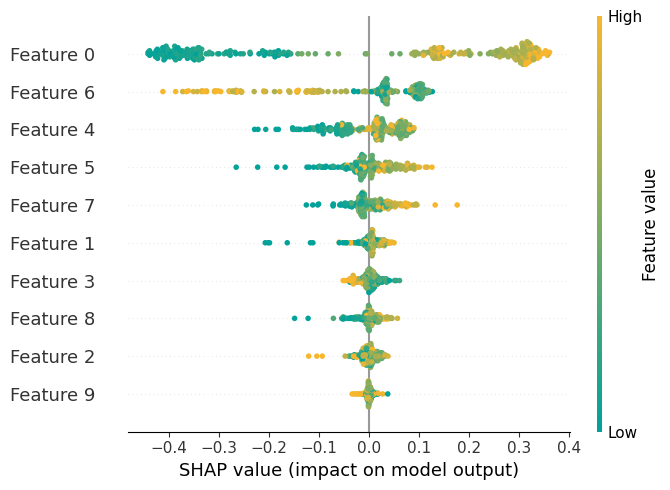

：Cluster4_Summary_Plot.pdf


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import matplotlib.colors as mcolors


shap_array = np.array(shap_values)


cluster_4_values = shap_array[:, :new_data.shape[1], 4]


fixed_width = 7
fixed_height = 5



custom_colors = ["#00A29A", "#F8B62D"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_shap_cmap", custom_colors)
# --------------------------------------------------------


print(" PDF...")


plt.figure(facecolor='white')


shap.summary_plot(
    cluster_4_values,
    new_data,
    plot_size=(fixed_width, fixed_height),
    cmap=custom_cmap,
    show=False
)


fig = plt.gcf()
fig.set_facecolor('white')



plt.savefig("Cluster4_Summary_Plot.pdf", bbox_inches='tight', facecolor='white')


plt.show()

print("：Cluster4_Summary_Plot.pdf")

In [7]:
import pandas as pd
import numpy as np


shap_array = np.array(shap_values)
cluster_0_values = shap_array[:, :, 4]



feature_names = [f"Feature {i}" for i in range(new_data.shape[1])]


importances = np.abs(cluster_0_values).mean(axis=0)

sorted_indices = np.argsort(importances)[::-1]


export_data = []
for idx in sorted_indices:
    col_name = feature_names[idx]
    temp_df = pd.DataFrame({
        'Feature_Name': col_name,
        'SHAP_Value': cluster_0_values[:, idx],
        'Actual_Value': new_data[:, idx],
        'Importance_Rank': importances[idx]
    })
    export_data.append(temp_df)


df_origin = pd.concat(export_data, axis=0)
df_origin.to_csv("SHAP_Sorted_For_Origin.csv", index=False)

print("。")

。


In [8]:
import pandas as pd
import numpy as np





cluster_0_values = shap_array[:, :, 4]


export_data = []


for i in range(new_data.shape[1]):
    col_name = f"Feature_{i}"
    temp_df = pd.DataFrame({
        'Feature_Name': col_name,
        'SHAP_Value': cluster_0_values[:, i],
        'Actual_Value': new_data[:, i]
    })
    export_data.append(temp_df)


df_origin = pd.concat(export_data, axis=0)


df_origin.to_csv("SHAP_Origin_Export.csv", index=False)
print("！ SHAP_Origin_Export.csv")

！ SHAP_Origin_Export.csv


In [9]:
print(new_data[14])

[ 0.47808943  0.12311576  0.45106053 -0.2319014  -0.12077767 -0.14532088
  0.0639294   0.57836429 -0.10764046  0.06318799]


 13 : 4


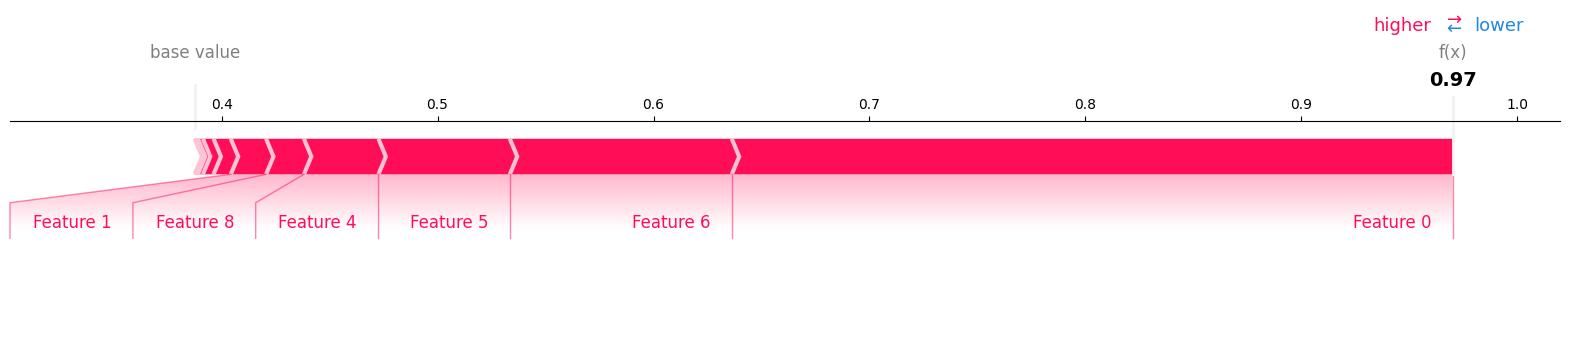

In [10]:


shap.initjs()

sample_idx = 13
predicted_cluster = labels[sample_idx]
print(f" {sample_idx} : {predicted_cluster}")



specific_shap_vector = shap_values[sample_idx].T[predicted_cluster]



custom_colors = ["#00A29A", "#F8B62D"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_shap_cmap", custom_colors)




if len(specific_shap_vector) > new_data.shape[1]:
    specific_shap_vector = specific_shap_vector[:-1]
my_feature_names = ["Feature 0", "Feature 1", "Feature 2", "Feature 3", "Feature 4", "Feature 5", "Feature 6", "Feature 7", "Feature 8", "Feature 9"]

shap.force_plot(
    explainer.expected_value[predicted_cluster],
    specific_shap_vector,


    matplotlib=True,
    show=False)
fig = plt.gcf()
plt.savefig("my_plot_RbK2Li.pdf", bbox_inches='tight')
plt.show()

 244 : 4


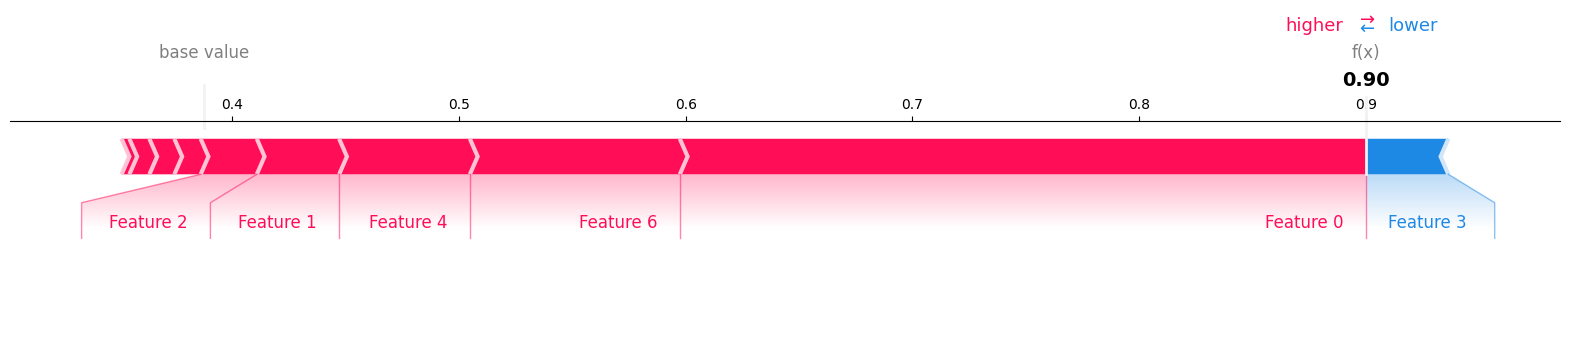

In [11]:


shap.initjs()

sample_idx = 244
predicted_cluster = labels[sample_idx]
print(f" {sample_idx} : {predicted_cluster}")



specific_shap_vector = shap_values[sample_idx].T[predicted_cluster]



if len(specific_shap_vector) > new_data.shape[1]:
    specific_shap_vector = specific_shap_vector[:-1]
my_feature_names = ["Feature 0", "Feature 1", "Feature 2", "Feature 3", "Feature 4", "Feature 5", "Feature 6", "Feature 7", "Feature 8", "Feature 9"]

shap.force_plot(
    explainer.expected_value[predicted_cluster],
    specific_shap_vector,


    matplotlib=True,
    show=False)
fig = plt.gcf()
plt.savefig("my_plot-Li2Ca.pdf", bbox_inches='tight')
plt.show()